# 10 · Beyond one hourly series: totals, a daily horizon and a panel of stores

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/10_frequency_and_panel.ipynb)

Companion notebook for *Chronos-2 in Practice (7/7)*.

Every experiment so far forecast one hourly series, one day ahead. This notebook leaves that
setting in three directions.

**What you will learn**

- How to forecast a **total** (the energy of tomorrow) when the model returns one quantile per
  hour: what the sum of hourly quantiles assumes, what independence assumes, and how both
  compare with forecasting the daily series directly.
- What changes at **another frequency**: the same load as a daily series, a week ahead.
- How Chronos-2 behaves on a **panel**: 1,115 retail stores from fev-bench, daily, with
  promotions and holidays known in advance, scored per window as the benchmark does and per
  store as a retailer would.

Runtime: ~6 min on a GPU (FAST_MODE: ~4 min on a CPU, on 30 stores).

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time
from dataclasses import replace

import pandas as pd
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.aggregate import aggregate_forecasts, daily_totals
from c2p.baselines import MSTL, PublishedForecast, SeasonalNaive
from c2p.config import get_device, get_paths, is_fast_mode, set_seed
from c2p.conformal import calibrate, conformalize
from c2p.data import spain_energy_frame, validate_and_prepare
from c2p.eval import (
    ACTUAL_COL,
    MODEL_COL,
    WINDOW_COL,
    BacktestConfig,
    backtest,
    error_by_series,
    evaluate,
    skill_table,
    summarize,
)
from c2p.experiments import (
    DAY_AHEAD_BLOCK,
    FREQ,
    LOAD,
    TSO_LOAD_FORECAST,
    VALIDATION_END,
    day_ahead_config,
    rotating_sample_config,
)
from c2p.fev_tasks import (
    assert_cutoffs_match,
    load_fev_task,
    task_backtest_config,
    task_series_frame,
)
from c2p.models import Chronos2Forecaster, load_chronos2
from c2p.plots.evaluation import plot_coverage, plot_skill_scores
from c2p.plotting import save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)  # True: 12 windows, and 30 stores instead of 1,115
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cuda
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-27 07:19
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: NVIDIA GeForce RTX 3070 (8 GiB)
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. The energy of tomorrow

A day-ahead forecast is 24 numbers with 24 intervals. Plenty of decisions need one number: the
energy to buy for the whole day, the sales of the whole week. The point forecast of a total is
the sum of the hourly point forecasts, and nobody disputes it. The interval is the problem.

Chronos-2 returns **marginal quantiles**: for each hour, the values that hour will stay below
with a given probability. It does not return sample paths, so it says nothing about how the
errors of different hours move together, and the interval of a sum depends on that:

- If the hourly errors move together perfectly (a cold day is cold all day), the 0.9 quantile
  of the total is the sum of the hourly 0.9 quantiles. This is the widest the marginals allow.
- If the hourly errors are unrelated, they partly cancel, and each hour's distance from its
  median adds in quadrature, like variances. This is much narrower.

`aggregate_forecasts` implements both, and `daily_totals` builds the alternative that needs no
assumption: the same load as a daily series, forecast one step ahead. A day here is the
day-ahead horizon of the rest of the series, 23:00 UTC to 22:00 UTC (midnight to midnight in
Madrid in winter).

In [3]:
pipeline = load_chronos2(device=DEVICE)
chronos = Chronos2Forecaster(pipeline)

In [4]:
raw = spain_energy_frame()[[ID_COL, TIMESTAMP_COL, LOAD, TSO_LOAD_FORECAST]]
hourly, _ = validate_and_prepare(raw, freq=FREQ, target=LOAD)
daily = daily_totals(hourly, [LOAD, TSO_LOAD_FORECAST])
missing = int(daily[LOAD].isna().sum())
print(
    f"{len(hourly):,} hours -> {len(daily):,} days, {daily[TIMESTAMP_COL].min().date()} to "
    f"{daily[TIMESTAMP_COL].max().date()}; {missing} days have a missing hour and no total"
)

HOURLY = day_ahead_config(FAST_MODE, max_context=2048)
HOURLY_OPERATOR = replace(HOURLY, known_covariates=(TSO_LOAD_FORECAST,))
# The same cutoffs on the daily grid: one step ahead, a weekly season, all the history.
DAILY = BacktestConfig(
    prediction_length=1,
    n_windows=HOURLY.n_windows,
    step=HOURLY.stride // 24,
    freq="D",
    season_length=7,
    target=LOAD,
)
LEVELS = HOURLY.quantile_levels

hourly_load = hourly[[ID_COL, TIMESTAMP_COL, LOAD]]
daily_load = daily[[ID_COL, TIMESTAMP_COL, LOAD]]

start = time.perf_counter()
hourly_forecasts = backtest(chronos, hourly_load, HOURLY)
operator_forecasts = backtest(
    PublishedForecast(TSO_LOAD_FORECAST, name="operator forecast"), hourly, HOURLY_OPERATOR
)
totals = {
    "daily series, forecast directly": backtest(
        Chronos2Forecaster(pipeline, name="daily series, forecast directly"), daily_load, DAILY
    ),
    "hourly quantiles, summed": aggregate_forecasts(
        hourly_forecasts,
        quantile_levels=LEVELS,
        method="comonotonic",
        name="hourly quantiles, summed",
    ),
    "hourly quantiles, independent hours": aggregate_forecasts(
        hourly_forecasts,
        quantile_levels=LEVELS,
        method="independent",
        name="hourly quantiles, independent hours",
    ),
    "operator forecast, summed": aggregate_forecasts(
        operator_forecasts,
        quantile_levels=LEVELS,
        method="comonotonic",
        name="operator forecast, summed",
    ),
    "seasonal_naive": backtest(SeasonalNaive(season_length=7), daily_load, DAILY),
}
print(f"{len(totals)} forecasts of the daily total in {time.perf_counter() - start:.0f} s")

metrics = pd.concat(
    [evaluate(frame, daily_load, DAILY) for frame in totals.values()], ignore_index=True
)
# A day with a missing hour has no total to score: drop its window for every model.
scored = metrics.groupby(WINDOW_COL)["WQL"].transform(lambda values: values.notna().all())
print(f"{int((~scored).sum() / len(totals))} windows dropped for a missing actual")
print("Saved", save_results(metrics[scored], "10_daily_total_metrics", PATHS).name)

35,064 hours -> 1,461 days, 2015-01-01 to 2018-12-31; 18 days have a missing hour and no total
5 forecasts of the daily total in 52 s
2 windows dropped for a missing actual
Saved 10_daily_total_metrics.csv


In [5]:
total_metrics = load_results("10_daily_total_metrics", PATHS)
total_summary = summarize(total_metrics)
OPERATOR = "operator forecast, summed"
# A point forecast has no interval to cover anything.
intervals = [column for column in total_summary.columns if column.startswith("coverage_")]
total_summary.loc[total_summary[MODEL_COL] == OPERATOR, intervals] = float("nan")
total_skill = skill_table(
    total_metrics,
    baseline="seasonal_naive",
    metric="WQL",
    block_length=1 if FAST_MODE else DAY_AHEAD_BLOCK,
)
total_summary = total_summary.merge(
    total_skill[[MODEL_COL, "skill", "ci_low", "ci_high"]], on=MODEL_COL
)
print("Saved", save_results(total_summary, "10_daily_total_summary", PATHS).name)

print(f"{'forecast of the daily total':<38} {'WQL':>7} {'WAPE':>7} {'80%':>6} {'98%':>6}  skill")
for row in total_summary.sort_values("WQL").itertuples():
    cov80 = "n/a" if pd.isna(row.coverage_80) else f"{row.coverage_80:.1%}"
    cov98 = "n/a" if pd.isna(row.coverage_98) else f"{row.coverage_98:.1%}"
    print(
        f"{row.model:<38} {row.WQL:7.4f} {row.WAPE:7.2%} {cov80:>6} {cov98:>6}  "
        f"{row.skill:+6.1%} [{row.ci_low:+.1%}, {row.ci_high:+.1%}]"
    )

Saved 10_daily_total_summary.csv
forecast of the daily total                WQL    WAPE    80%    98%  skill
operator forecast, summed               0.0068   0.68%    n/a    n/a  +91.1% [+89.9%, +92.2%]
hourly quantiles, summed                0.0343   4.12%  79.1%  94.8%  +67.8% [+62.4%, +72.4%]
hourly quantiles, independent hours     0.0382   4.12%  30.3%  63.4%  +73.4% [+67.3%, +78.3%]
daily series, forecast directly         0.0411   5.17%  80.4%  98.1%  +51.1% [+44.5%, +56.6%]
seasonal_naive                          0.0709   8.58%  80.4%  95.9%   +0.0% [+0.0%, +0.0%]


Saved 10_daily_total_coverage.csv


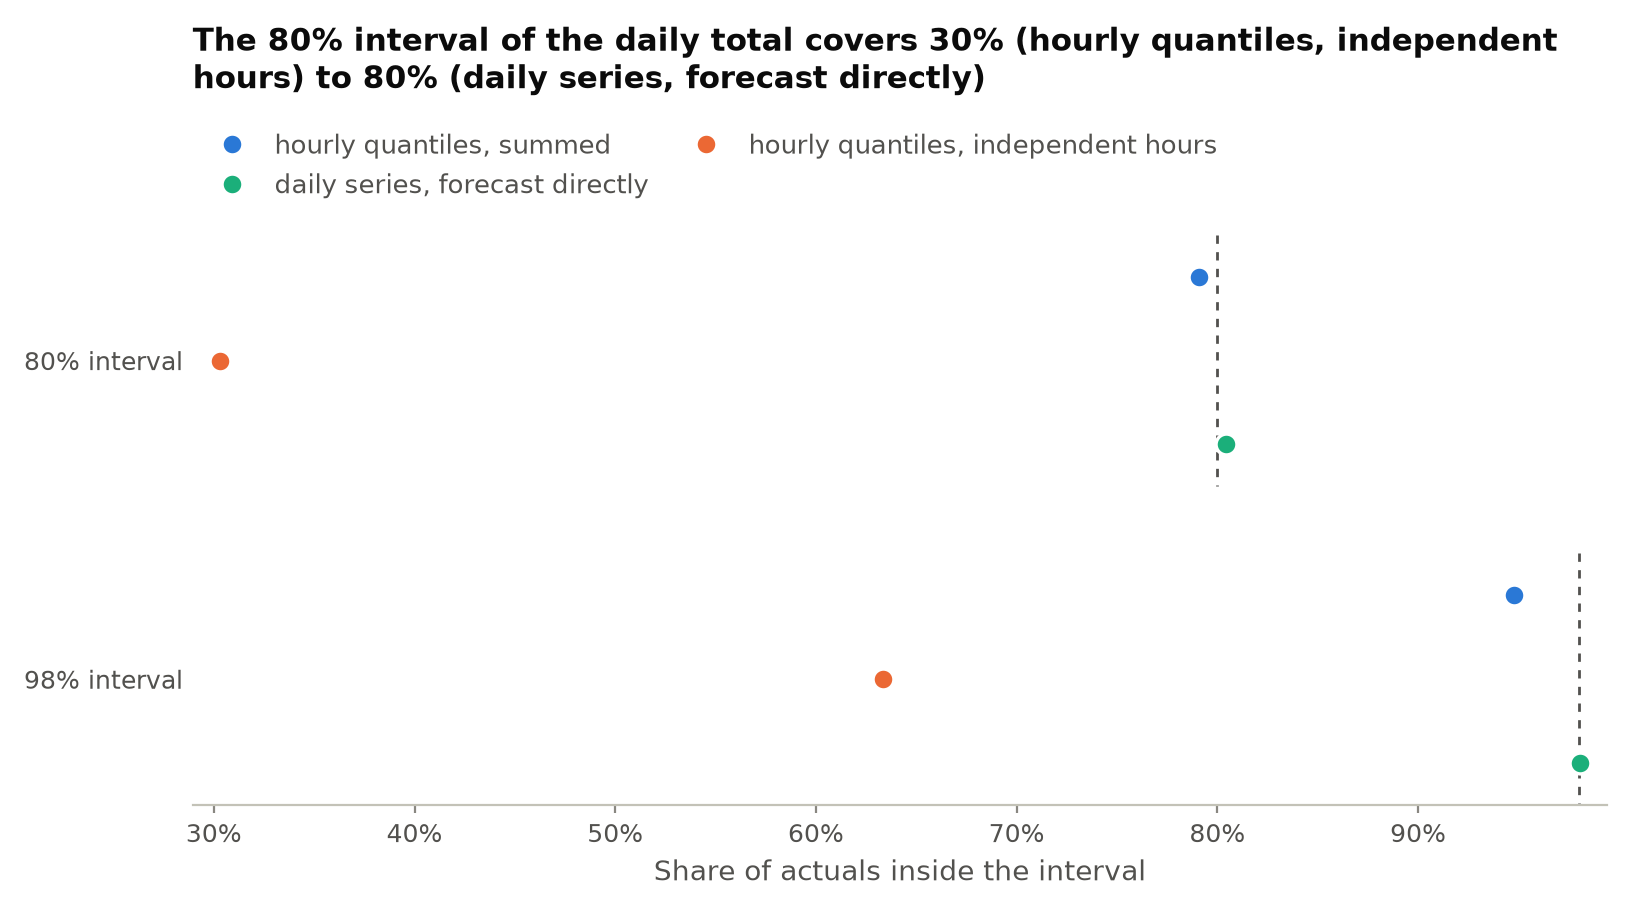

In [6]:
total_summary = load_results("10_daily_total_summary", PATHS)
probabilistic = total_summary[~total_summary[MODEL_COL].isin([OPERATOR, "seasonal_naive"])]
coverage = pd.concat(
    [
        pd.DataFrame(
            {
                MODEL_COL: probabilistic[MODEL_COL],
                "nominal": nominal,
                "achieved": probabilistic[column],
            }
        )
        for nominal, column in ((0.8, "coverage_80"), (0.98, "coverage_98"))
    ],
    ignore_index=True,
)
print("Saved", save_results(coverage, "10_daily_total_coverage", PATHS).name)

coverage = load_results("10_daily_total_coverage", PATHS)
at_80 = coverage[coverage["nominal"] == 0.8].set_index(MODEL_COL)["achieved"]
title = (
    f"The 80% interval of the daily total covers {at_80.min():.0%} ({at_80.idxmin()}) "
    f"to {at_80.max():.0%} ({at_80.idxmax()})"
)
ax = plot_coverage(coverage, colors={}, title=title)
(figure_path,) = save_figure(ax.figure, "10_daily_total_coverage", PATHS.figures)
display(Image(filename=figure_path, width=800))

### Calibrating the total

Summing the hourly quantiles landed near 80%, and the reason is not reassuring: the hourly
intervals are too narrow (Part 2), perfect dependence is too wide, and here the two cancel.
Part 6 repaired the hourly intervals with a conformal correction learned on the second half
of 2017. The same correction can be used in two places:

- **calibrate the hours, then sum.** Each hourly interval is now right on its own, and the sum
  still assumes that all 24 errors move together;
- **sum, then calibrate the total.** The summed forecast is a forecast of a daily series like
  any other: measure by how much its interval missed the daily totals of the calibration
  period, and shift it by that much. No assumption about the dependence is left.

In [7]:
before_2018 = hourly_load[hourly_load[TIMESTAMP_COL] <= VALIDATION_END]
CALIBRATION = replace(HOURLY, n_windows=12 if FAST_MODE else 184)  # the second half of 2017
calibration_hours = backtest(chronos, before_2018, CALIBRATION)
assert calibration_hours[TIMESTAMP_COL].max() <= VALIDATION_END


def summed(frame: pd.DataFrame, name: str) -> pd.DataFrame:
    """The daily total under perfect dependence: the hourly quantiles, added up."""
    return aggregate_forecasts(frame, quantile_levels=LEVELS, method="comonotonic", name=name)


# Route 1: calibrate each hour as in Part 6, then sum the calibrated quantiles.
hourly_calibration = calibrate(calibration_hours, quantile_levels=LEVELS)
calibrated_hours = conformalize(hourly_forecasts, hourly_calibration, quantile_levels=LEVELS)

# Route 2: sum first, then calibrate the total against the daily totals of the same period.
daily_actual = daily_load.rename(columns={LOAD: ACTUAL_COL})
calibration_totals = summed(calibration_hours, "calibration").merge(
    daily_actual, on=[ID_COL, TIMESTAMP_COL]
)
total_calibration = calibrate(calibration_totals, quantile_levels=LEVELS)
shift = total_calibration.delta(0.1, 0.9).iloc[0]
last_day = calibration_totals[TIMESTAMP_COL].max().date()
print(
    f"Calibration: {CALIBRATION.n_windows} days up to {last_day}; "
    f"the 80% interval of the total moves by {shift:+,.0f} MWh on each side "
    f"({shift / daily_load[LOAD].mean():+.2%} of an average day)"
)

SUMMED = "hourly quantiles, summed"
calibrated = [
    summed(calibrated_hours, "calibrated hours, summed"),
    conformalize(totals[SUMMED], total_calibration, quantile_levels=LEVELS).assign(
        **{MODEL_COL: "summed, then calibrated"}
    ),
]
scored_windows = load_results("10_daily_total_metrics", PATHS)
calibrated_metrics = pd.concat(
    [evaluate(frame, daily_load, DAILY) for frame in calibrated], ignore_index=True
)
calibrated_metrics = pd.concat(
    [
        scored_windows[scored_windows[MODEL_COL] == SUMMED],
        calibrated_metrics[calibrated_metrics[WINDOW_COL].isin(scored_windows[WINDOW_COL])],
    ],
    ignore_index=True,
)
print("Saved", save_results(calibrated_metrics, "10_total_calibration_metrics", PATHS).name)

calibrated_summary = summarize(load_results("10_total_calibration_metrics", PATHS))
print("Saved", save_results(calibrated_summary, "10_total_calibration_summary", PATHS).name)
print(f"\n{'forecast of the daily total':<28} {'WQL':>7} {'80%':>6} {'98%':>6}")
for row in calibrated_summary.itertuples():
    print(f"{row.model:<28} {row.WQL:7.4f} {row.coverage_80:6.1%} {row.coverage_98:6.1%}")

Calibration: 184 days up to 2017-12-31; the 80% interval of the total moves by +9,861 MWh on each side (+1.43% of an average day)
Saved 10_total_calibration_metrics.csv
Saved 10_total_calibration_summary.csv

forecast of the daily total      WQL    80%    98%
hourly quantiles, summed      0.0343  79.1%  94.8%
summed, then calibrated       0.0343  83.2%  98.9%
calibrated hours, summed      0.0345  85.1%  98.9%


## 2. Another frequency: a week of daily totals

The same question at a longer horizon is also a question about frequency. A week ahead can be
168 hourly steps, summed into seven days, or seven steps of the daily series. The daily series
is short (four years are 1,461 points, less than one context of the hourly protocol) and has
lost the daily cycle; what it keeps is the weekly one. The windows are the rotating sample of
notebook `03`: one every eight days, so the horizons do not overlap and every weekday starts
a forecast.

In [8]:
WEEK_HOURLY = rotating_sample_config(
    FAST_MODE, prediction_length=168, step_days=8, max_context=2048
)
WEEK_DAILY = BacktestConfig(
    prediction_length=7,
    n_windows=WEEK_HOURLY.n_windows,
    step=WEEK_HOURLY.stride // 24,
    freq="D",
    season_length=7,
    target=LOAD,
)
start = time.perf_counter()
week_hourly = backtest(chronos, hourly_load, WEEK_HOURLY)
week = {
    "daily series, forecast directly": backtest(
        Chronos2Forecaster(pipeline, name="daily series, forecast directly"),
        daily_load,
        WEEK_DAILY,
    ),
    "hourly quantiles, summed": aggregate_forecasts(
        week_hourly, quantile_levels=LEVELS, method="comonotonic", name="hourly quantiles, summed"
    ),
    "mstl": backtest(MSTL(season_lengths=(7,)), daily_load, WEEK_DAILY),
    "seasonal_naive": backtest(SeasonalNaive(season_length=7), daily_load, WEEK_DAILY),
}
print(
    f"{WEEK_DAILY.n_windows} windows of 7 days, {len(week)} models, "
    f"{time.perf_counter() - start:.0f} s"
)
week_metrics = pd.concat(
    [evaluate(frame, daily_load, WEEK_DAILY) for frame in week.values()], ignore_index=True
)
print("Saved", save_results(week_metrics, "10_week_ahead_metrics", PATHS).name)

week_metrics = load_results("10_week_ahead_metrics", PATHS)
week_summary = summarize(week_metrics).merge(
    skill_table(week_metrics, baseline="seasonal_naive", metric="WQL")[
        [MODEL_COL, "skill", "ci_low", "ci_high", "win_rate"]
    ],
    on=MODEL_COL,
)
print("Saved", save_results(week_summary, "10_week_ahead_summary", PATHS).name)
columns = [MODEL_COL, "WQL", "MASE", "WAPE", "coverage_80", "skill", "ci_low", "ci_high"]
week_summary.sort_values("WQL")[columns].round(4)

45 windows of 7 days, 4 models, 9 s
Saved 10_week_ahead_metrics.csv
Saved 10_week_ahead_summary.csv


,model,WQL,MASE,WAPE,coverage_80,skill,ci_low,ci_high
0,"daily series, forecast directly",0.0414,0.6381,0.0526,0.8206,0.4855,0.4126,0.5487
1,"hourly quantiles, summed",0.0455,0.6631,0.0546,0.7868,0.4393,0.3628,0.5070
2,mstl,0.0551,0.8348,0.0688,0.8085,0.2311,0.1662,0.2983
3,seasonal_naive,0.0703,1.0244,0.0845,0.8042,0.0000,0.0000,0.0000


## 3. A panel: 1,115 stores, daily, with promotions

One series was a convenient place to learn the protocol. Most forecasting work is a panel: a
thousand stores, ten thousand products. fev-bench has the Rossmann store sales as a task
(`rossmann_1D`): 1,115 stores, daily sales over two and a half years, a 48-day horizon, ten
windows. Each store has five covariates known in advance (whether it is open, whether a
promotion runs, school and state holidays, the weekday) and one that is only observed (the
number of customers). `StateHoliday` is text, which `task_series_frame` keeps as a category.

As with EPF-DE in notebook `05`, the task is the published one: the cutoffs our harness
derives are checked against fev's before anything is scored.

Four ways to give it to Chronos-2, plus the seasonal naive as the reference:

- **History only**: each store's own sales and nothing else.
- **+known covariates**: the five columns whose future is known.
- **+known and past covariates**: the customers as well, which stop at the cutoff.
- **+known covariates, cross-learning**: stores in the same batch share information.

In [9]:
task = load_fev_task("rossmann_1D")
panel = task_series_frame(task)
TARGET = str(task.target)
KNOWN = tuple(task.known_dynamic_columns)
PAST = tuple(task.past_dynamic_columns)
PANEL_KNOWN = task_backtest_config(task, n_windows=2 if FAST_MODE else None)
if FAST_MODE:
    panel = panel[panel[ID_COL].isin(sorted(panel[ID_COL].unique())[:30])]
else:
    assert_cutoffs_match(task, panel, PANEL_KNOWN)
PANEL_PLAIN = replace(PANEL_KNOWN, known_covariates=())
print(
    f"{panel[ID_COL].nunique():,} stores, {len(panel):,} rows, "
    f"{panel[TIMESTAMP_COL].min().date()} to {panel[TIMESTAMP_COL].max().date()}"
)
print(f"target {TARGET}; known in advance {KNOWN}; observed only {PAST}")
print(PANEL_KNOWN)

base = [ID_COL, TIMESTAMP_COL, TARGET]

1,115 stores, 1,050,330 rows, 2013-01-01 to 2015-07-31
target Sales; known in advance ('DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'StateHoliday'); observed only ('Customers',)
BacktestConfig(prediction_length=48, n_windows=10, freq='D', season_length=7, step=48, quantile_levels=(0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.99), target='Sales', known_covariates=('DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'StateHoliday'), max_context=None)


In [10]:
ARMS = {
    "seasonal_naive": (SeasonalNaive(season_length=7), panel[base], PANEL_PLAIN),
    "history only": (
        Chronos2Forecaster(pipeline, name="history only"),
        panel[base],
        PANEL_PLAIN,
    ),
    "+known covariates": (
        Chronos2Forecaster(pipeline, name="+known covariates"),
        panel[[*base, *KNOWN]],
        PANEL_KNOWN,
    ),
    "+known and past covariates": (
        Chronos2Forecaster(pipeline, name="+known and past covariates"),
        panel[[*base, *KNOWN, *PAST]],
        PANEL_KNOWN,
    ),
    "+known covariates, cross-learning": (
        Chronos2Forecaster(
            pipeline, name="+known covariates, cross-learning", cross_learning=True, batch_size=100
        ),
        panel[[*base, *KNOWN]],
        PANEL_KNOWN,
    ),
}
window_metrics, store_errors = [], []
for name, (model, frame, config) in ARMS.items():
    forecasts = backtest(model, frame, config)
    window_metrics.append(evaluate(forecasts, frame, config))
    store_errors.append(error_by_series(forecasts))
    seconds = window_metrics[-1]["seconds"].mean()
    print(
        f"  {name:<36} WQL {window_metrics[-1]['WQL'].mean():.4f}  "
        f"{seconds:6.1f} s per window, {frame[ID_COL].nunique() / seconds:7.0f} stores/s"
    )
print("Saved", save_results(pd.concat(window_metrics), "10_panel_metrics", PATHS).name)
print("Saved", save_results(pd.concat(store_errors), "10_panel_store_errors", PATHS).name)

  seasonal_naive                       WQL 0.3122     1.0 s per window,    1064 stores/s
  history only                         WQL 0.1632     2.4 s per window,     462 stores/s
  +known covariates                    WQL 0.0927    12.3 s per window,      90 stores/s
  +known and past covariates           WQL 0.0935    14.4 s per window,      77 stores/s
  +known covariates, cross-learning    WQL 0.0953    11.8 s per window,      94 stores/s
Saved 10_panel_metrics.csv
Saved 10_panel_store_errors.csv


src/c2p/eval.py:522: UserWarning: cross_learning=True over 1115 series with batch_size=100: every series in a batch joins one group, so the forecast depends on how the frame is cut into batches. The library suggests about 100 series per batch (the size used in the technical report); prefer that and frames of related series.
  forecast = forecaster.predict(


Two ways to read the same forecasts. **Per window** is how the benchmark scores the task: all
stores of a window pooled into one number, ten windows, the skill as the geometric mean over
them. **Per store** pools each store's ten windows instead and asks on how many stores the
model beats the reference, which is the question a retailer asks; with 1,115 stores to resample,
its interval is also much tighter than one built on ten windows.

In [11]:
panel_metrics = load_results("10_panel_metrics", PATHS)
by_window = skill_table(panel_metrics, baseline="seasonal_naive", metric="WQL")

store_errors = load_results("10_panel_store_errors", PATHS)
# A store that was closed for the whole test period has no error to compare.
usable = (
    store_errors.groupby(ID_COL)["WQL"]
    .transform(lambda values: values.notna().all() and (values > 0).all())
    .astype(bool)
)
print(f"{store_errors.loc[~usable, ID_COL].nunique()} stores left out: no sales to score")
by_store = skill_table(store_errors[usable], baseline="seasonal_naive", metric="WQL", unit=ID_COL)

means = summarize(panel_metrics).set_index(MODEL_COL)
panel_summary = (
    by_window.set_index(MODEL_COL)[["skill", "ci_low", "ci_high", "n_units"]]
    .add_prefix("window_")
    .join(
        by_store.set_index(MODEL_COL)[
            ["skill", "ci_low", "ci_high", "win_rate", "n_units"]
        ].add_prefix("store_")
    )
    .join(means[["WQL", "MASE", "WAPE", "coverage_80", "seconds"]])
    .reset_index()
)
panel_summary["stores_per_second"] = panel[ID_COL].nunique() / panel_summary["seconds"]
print("Saved", save_results(panel_summary, "10_panel_summary", PATHS).name)
print("Saved", save_results(by_store, "10_panel_store_skill", PATHS).name)

print(
    f"{'arm':<36} {'per window (benchmark)':<26} {'per store':<26} {'stores won':>10} {'cov80':>6}"
)
for row in panel_summary.sort_values("store_skill", ascending=False).itertuples():
    if row.model == "seasonal_naive":
        continue
    print(
        f"{row.model:<36} "
        f"{row.window_skill:+6.1%} [{row.window_ci_low:+.1%}, {row.window_ci_high:+.1%}]   "
        f"{row.store_skill:+6.1%} [{row.store_ci_low:+.1%}, {row.store_ci_high:+.1%}]   "
        f"{row.store_win_rate:>9.0%} {row.coverage_80:>6.1%}"
    )

0 stores left out: no sales to score
Saved 10_panel_summary.csv
Saved 10_panel_store_skill.csv
arm                                  per window (benchmark)     per store                  stores won  cov80
+known covariates                    +70.6% [+68.0%, +72.5%]   +70.2% [+70.0%, +70.4%]        100%  84.9%
+known and past covariates           +70.4% [+67.8%, +72.2%]   +69.9% [+69.7%, +70.1%]        100%  84.4%
+known covariates, cross-learning    +69.9% [+66.6%, +72.5%]   +69.6% [+69.3%, +69.8%]        100%  85.3%
history only                         +49.3% [+42.3%, +55.9%]   +47.7% [+47.5%, +48.0%]        100%  75.4%


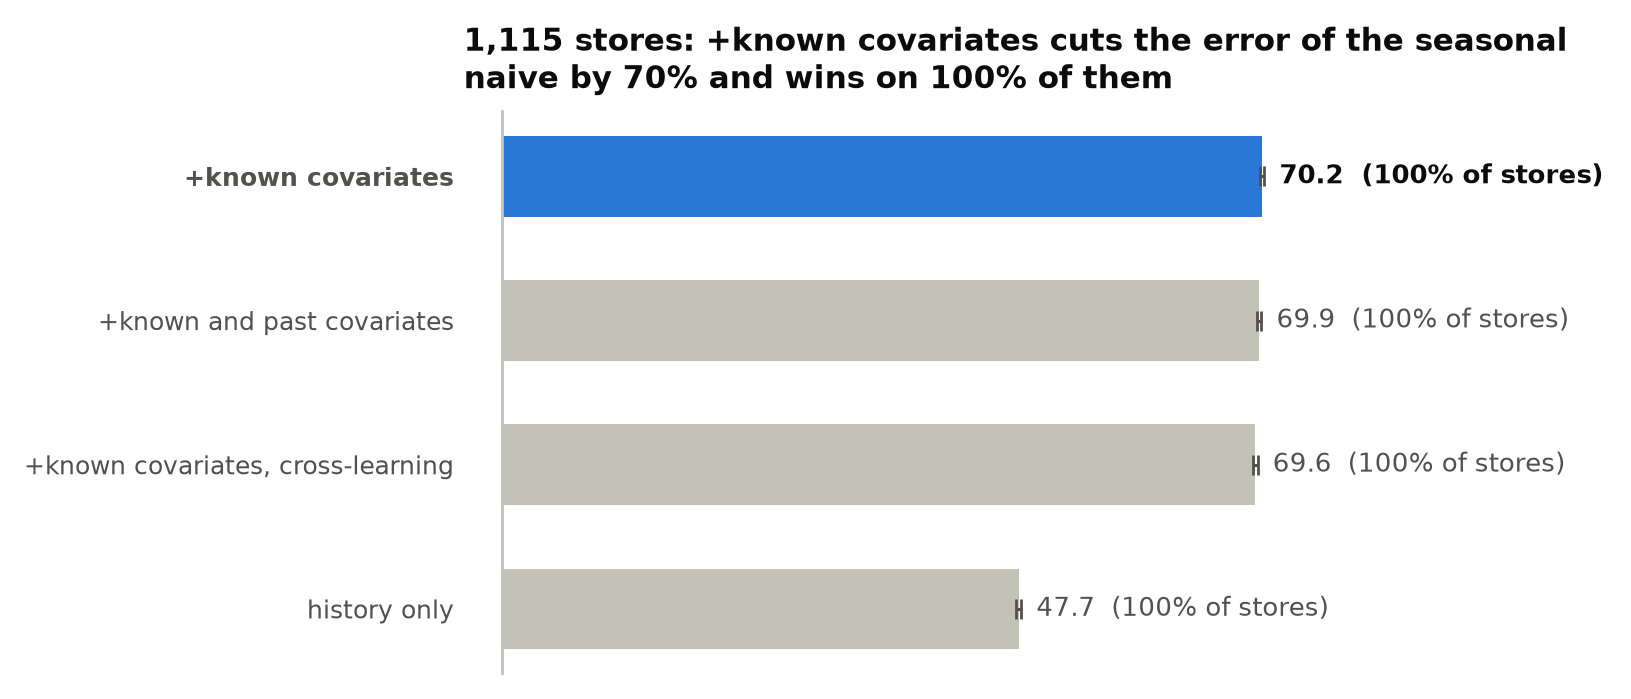

In [12]:
by_store = load_results("10_panel_store_skill", PATHS)
best = by_store[by_store[MODEL_COL] != "seasonal_naive"].iloc[0]
title = (
    f"{int(best['n_units']):,} stores: {best[MODEL_COL]} cuts the error of the seasonal naive "
    f"by {best['skill']:.0%} and wins on {best['win_rate']:.0%} of them"
)
ax = plot_skill_scores(
    by_store,
    highlight=str(best[MODEL_COL]),
    title=title,
    xlabel="WQL improvement over the seasonal naive (%), stores as units",
    units="stores",
)
(figure_path,) = save_figure(ax.figure, "10_panel_skill", PATHS.figures)
display(Image(filename=figure_path, width=800))

### Which of the five covariates carries the gain

The five known covariates went in together. To see what each one contributes, each is left out
in turn and the forecast is compared, store by store and window by window, with the one that
had all five. One of the five is a category: `StateHoliday` is text (`0`, `a`, `b`, `c`), and
with a single target Chronos-2 turns each label into the store's own average sales under that
label before the model sees it. A sixth arm leaves out `Open` and `StateHoliday` together:
`Open` says that a store is closed, the holiday is one of the reasons why, and the pair shows
what the category can carry when the flag is gone.


In [13]:
FULL = "+known covariates"
DROPPED = {f"without {column}": (column,) for column in KNOWN}
DROPPED["without Open and StateHoliday"] = ("Open", "StateHoliday")
print({column: str(panel[column].dtype) for column in KNOWN})

window_metrics, store_errors = [], []
for name, dropped in DROPPED.items():
    kept = tuple(column for column in KNOWN if column not in dropped)
    frame, config = panel[[*base, *kept]], replace(PANEL_KNOWN, known_covariates=kept)
    forecasts = backtest(Chronos2Forecaster(pipeline, name=name), frame, config)
    window_metrics.append(evaluate(forecasts, frame, config))
    store_errors.append(error_by_series(forecasts))
    print(f"  {name:<32} WQL {window_metrics[-1]['WQL'].mean():.4f}")
print(
    "Saved",
    save_results(pd.concat(window_metrics), "10_panel_covariates_metrics", PATHS).name,
)
print(
    "Saved",
    save_results(pd.concat(store_errors), "10_panel_covariates_store_errors", PATHS).name,
)

# Paired with the arm that had all five: negative means that leaving the covariate out hurts.
all_five = load_results("10_panel_metrics", PATHS)
all_five_stores = load_results("10_panel_store_errors", PATHS)
windows = pd.concat(
    [
        all_five[all_five[MODEL_COL] == FULL],
        load_results("10_panel_covariates_metrics", PATHS),
    ],
    ignore_index=True,
)
stores = pd.concat(
    [
        all_five_stores[all_five_stores[MODEL_COL] == FULL],
        load_results("10_panel_covariates_store_errors", PATHS),
    ],
    ignore_index=True,
)
usable = (
    stores.groupby(ID_COL)["WQL"]
    .transform(lambda values: values.notna().all() and (values > 0).all())
    .astype(bool)
)
by_window = skill_table(windows, baseline=FULL, metric="WQL").set_index(MODEL_COL)
by_store = skill_table(stores[usable], baseline=FULL, metric="WQL", unit=ID_COL)
by_store = by_store.set_index(MODEL_COL)
covariate_skill = (
    by_window[["skill", "ci_low", "ci_high", "n_units"]]
    .add_prefix("window_")
    .join(by_store[["skill", "ci_low", "ci_high", "win_rate", "n_units"]].add_prefix("store_"))
    .join(summarize(windows).set_index(MODEL_COL)[["WQL", "coverage_80"]])
    .reset_index()
)
print("Saved", save_results(covariate_skill, "10_panel_covariates_skill", PATHS).name)
covariate_skill.round(4)

{'DayOfWeek': 'float64', 'Open': 'float64', 'Promo': 'float64', 'SchoolHoliday': 'float64', 'StateHoliday': 'category'}
  without DayOfWeek                WQL 0.0940
  without Open                     WQL 0.0970
  without Promo                    WQL 0.1211
  without SchoolHoliday            WQL 0.0939
  without StateHoliday             WQL 0.0936
  without Open and StateHoliday    WQL 0.1318
Saved 10_panel_covariates_metrics.csv
Saved 10_panel_covariates_store_errors.csv
Saved 10_panel_covariates_skill.csv


,model,window_skill,window_ci_low,window_ci_high,window_n_units,store_skill,store_ci_low,store_ci_high,store_win_rate,store_n_units,WQL,coverage_80
0,+known covariates,0.0000,0.0000,0.0000,10,0.0000,0.0000,0.0000,0.5000,1115,0.0927,0.8486
1,without StateHoliday,-0.0095,-0.0222,0.0007,10,-0.0093,-0.0110,-0.0078,0.2753,1115,0.0936,0.8553
2,without DayOfWeek,-0.0107,-0.0225,0.0019,10,-0.0141,-0.0148,-0.0133,0.1085,1115,0.0940,0.8526
3,without SchoolHoliday,-0.0118,-0.0240,-0.0001,10,-0.0130,-0.0142,-0.0118,0.1946,1115,0.0939,0.8505
4,without Open,-0.0464,-0.0719,-0.0186,10,-0.0418,-0.0454,-0.0385,0.1291,1115,0.0970,0.8559
5,without Promo,-0.3089,-0.3853,-0.2487,10,-0.3001,-0.3071,-0.2933,0.0027,1115,0.1211,0.7800
6,without Open and StateHoliday,-0.3887,-0.5710,-0.2100,10,-0.4299,-0.4364,-0.4237,0.0000,1115,0.1318,0.8376


### Static attributes: a store type is not a covariate

The dataset also describes each store once: its type, its assortment, the distance to the
nearest competitor. Chronos-2 has no input for attributes like these. The only way to hand
them over is as columns that repeat the same value at every timestamp, which is what
`task_series_frame(task, static_columns=...)` builds, so this cell tries it, with and without
cross-learning.

What to expect follows from how the model reads its inputs. Every input series is standardised
on its own before the model sees it, so a numeric column with one value per store arrives as a
row of zeros. A text column is replaced by the store's own average sales under each label, and
with a single label that is one number, standardised to zero in turn. Cross-learning lets the
stores of a batch attend to one another, but what they share has already lost the attribute.
So the columns cannot add information. What is left to measure is whether three more series in
every store's group cost anything.

In [14]:
STATIC = ("StoreType", "Assortment", "CompetitionDistance")
with_static = task_series_frame(task, static_columns=STATIC)
with_static = with_static[with_static[ID_COL].isin(panel[ID_COL].unique())]
print({column: str(with_static[column].dtype) for column in STATIC})
print(with_static.groupby(ID_COL)[list(STATIC)].first().head(3))

STATIC_CONFIG = replace(PANEL_KNOWN, known_covariates=(*KNOWN, *STATIC))
STATIC_ARMS = {
    "+known covariates and store attributes": Chronos2Forecaster(
        pipeline, name="+known covariates and store attributes"
    ),
    "+known covariates and store attributes, cross-learning": Chronos2Forecaster(
        pipeline,
        name="+known covariates and store attributes, cross-learning",
        cross_learning=True,
        batch_size=100,
    ),
}
static_frame = with_static[[*base, *KNOWN, *STATIC]]
static_errors = []
for name, model in STATIC_ARMS.items():
    forecasts = backtest(model, static_frame, STATIC_CONFIG)
    static_errors.append(error_by_series(forecasts))
    wql = evaluate(forecasts, static_frame, STATIC_CONFIG)["WQL"].mean()
    print(f"  {name:<56} WQL {wql:.4f}")
print(
    "Saved",
    save_results(pd.concat(static_errors), "10_panel_static_store_errors", PATHS).name,
)

# Each arm against the same arm without the attributes, store by store.
without = load_results("10_panel_store_errors", PATHS)
with_attributes = load_results("10_panel_static_store_errors", PATHS)
PAIRS = {name: name.replace(" and store attributes", "") for name in STATIC_ARMS}
rows = []
for name, reference in PAIRS.items():
    pair = pd.concat(
        [
            without[without[MODEL_COL] == reference],
            with_attributes[with_attributes[MODEL_COL] == name],
        ],
        ignore_index=True,
    )
    scored = (
        pair.groupby(ID_COL)["WQL"]
        .transform(lambda values: values.notna().all() and (values > 0).all())
        .astype(bool)
    )
    table = skill_table(pair[scored], baseline=reference, metric="WQL", unit=ID_COL)
    rows.append(table[table[MODEL_COL] == name])
static_skill = pd.concat(rows, ignore_index=True)
print("Saved", save_results(static_skill, "10_panel_static_skill", PATHS).name)
static_skill.round(5)

{'StoreType': 'category', 'Assortment': 'category', 'CompetitionDistance': 'float64'}
        StoreType Assortment  CompetitionDistance
item_id                                          
1               c          a               1270.0
10              a          a               3160.0
100             d          a              17930.0
  +known covariates and store attributes                   WQL 0.0939
  +known covariates and store attributes, cross-learning   WQL 0.0971
Saved 10_panel_static_store_errors.csv
Saved 10_panel_static_skill.csv


src/c2p/eval.py:522: UserWarning: cross_learning=True over 1115 series with batch_size=100: every series in a batch joins one group, so the forecast depends on how the frame is cut into batches. The library suggests about 100 series per batch (the size used in the technical report); prefer that and frames of related series.
  forecast = forecaster.predict(


,model,baseline,metric,skill,ci_low,ci_high,win_rate,n_units,block_length
0,+known covariates and store attributes,+known covariates,WQL,-0.01286,-0.01393,-0.01182,0.21704,1115,1
1,"+known covariates and store attributes, cross-...","+known covariates, cross-learning",WQL,-0.02080,-0.02207,-0.01951,0.15695,1115,1


## 4. The paired comparisons

The tables above score every arm against the seasonal naive. The questions of this notebook are
comparisons between two arms, and those are sharper when the two are paired window by window
(or store by store) before resampling. One file collects them for Part 7.

In [15]:
def paired(
    metrics: pd.DataFrame, model: str, baseline: str, comparison: str, **kwargs: object
) -> pd.DataFrame:
    """The skill of ``model`` over ``baseline``, each window (or store) compared with itself."""
    pair = metrics[metrics[MODEL_COL].isin([model, baseline])]
    table = skill_table(pair, baseline=baseline, metric="WQL", aggregate="both", **kwargs)
    return table[table[MODEL_COL] == model].assign(comparison=comparison)


total_metrics = load_results("10_daily_total_metrics", PATHS)
week_metrics = load_results("10_week_ahead_metrics", PATHS)
store_errors = load_results("10_panel_store_errors", PATHS)
scored = (
    store_errors.groupby(ID_COL)["WQL"]
    .transform(lambda values: values.notna().all() and (values > 0).all())
    .astype(bool)
)
stores = store_errors[scored]
KNOWN_ARM = "+known covariates"
paired_skill = pd.concat(
    [
        paired(
            total_metrics,
            "hourly quantiles, summed",
            "daily series, forecast directly",
            "tomorrow's total",
            block_length=1 if FAST_MODE else DAY_AHEAD_BLOCK,
        ),
        paired(
            week_metrics,
            "daily series, forecast directly",
            "hourly quantiles, summed",
            "a week of totals",
        ),
        paired(stores, KNOWN_ARM, "history only", "panel", unit=ID_COL),
        paired(stores, "+known and past covariates", KNOWN_ARM, "panel", unit=ID_COL),
        paired(stores, "+known covariates, cross-learning", KNOWN_ARM, "panel", unit=ID_COL),
    ],
    ignore_index=True,
)
print("Saved", save_results(paired_skill, "10_paired_skill", PATHS).name)
for row in paired_skill.itertuples():
    print(
        f"{row.comparison:<17} {row.model:<34} vs {row.baseline:<32} "
        f"{row.skill:+6.1%} [{row.ci_low:+.1%}, {row.ci_high:+.1%}]  wins {row.win_rate:.0%}"
    )

Saved 10_paired_skill.csv
tomorrow's total  hourly quantiles, summed           vs daily series, forecast directly  +34.3% [+28.1%, +39.9%]  wins 72%
a week of totals  daily series, forecast directly    vs hourly quantiles, summed          +8.2% [+0.0%, +15.5%]  wins 64%
panel             +known covariates                  vs history only                     +43.0% [+42.6%, +43.4%]  wins 100%
panel             +known and past covariates         vs +known covariates                 -0.9% [-1.0%, -0.9%]  wins 17%
panel             +known covariates, cross-learning  vs +known covariates                 -2.1% [-2.5%, -1.8%]  wins 36%


## Summary

In [16]:
total = load_results("10_daily_total_summary", PATHS).set_index(MODEL_COL)
week = load_results("10_week_ahead_summary", PATHS).set_index(MODEL_COL)
stores = load_results("10_panel_summary", PATHS).set_index(MODEL_COL)

print("Tomorrow's total, 80% interval:")
for name in (
    "hourly quantiles, summed",
    "hourly quantiles, independent hours",
    "daily series, forecast directly",
):
    print(
        f"  {name:<38} covers {total.loc[name, 'coverage_80']:.1%}, "
        f"WQL {total.loc[name, 'WQL']:.4f}"
    )

print("\nA week of daily totals, skill against the weekly seasonal naive:")
for name in week.sort_values("WQL").index:
    if name != "seasonal_naive":
        row = week.loc[name]
        print(f"  {name:<38} {row['skill']:+.1%} [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]")

print("\nRossmann panel, skill against the seasonal naive with stores as units:")
for name in stores.sort_values("store_skill", ascending=False).index:
    if name != "seasonal_naive":
        row = stores.loc[name]
        print(
            f"  {name:<38} {row['store_skill']:+.1%} "
            f"[{row['store_ci_low']:+.1%}, {row['store_ci_high']:+.1%}], "
            f"{row['stores_per_second']:,.0f} stores/s"
        )

Tomorrow's total, 80% interval:
  hourly quantiles, summed               covers 79.1%, WQL 0.0343
  hourly quantiles, independent hours    covers 30.3%, WQL 0.0382
  daily series, forecast directly        covers 80.4%, WQL 0.0411

A week of daily totals, skill against the weekly seasonal naive:
  daily series, forecast directly        +48.6% [+41.3%, +54.9%]
  hourly quantiles, summed               +43.9% [+36.3%, +50.7%]
  mstl                                   +23.1% [+16.6%, +29.8%]

Rossmann panel, skill against the seasonal naive with stores as units:
  +known covariates                      +70.2% [+70.0%, +70.4%], 90 stores/s
  +known and past covariates             +69.9% [+69.7%, +70.1%], 77 stores/s
  +known covariates, cross-learning      +69.6% [+69.3%, +69.8%], 94 stores/s
  history only                           +47.7% [+47.5%, +48.0%], 462 stores/s


**Next:** [`11_embeddings`](11_embeddings.ipynb) uses the same model without asking it for a
forecast at all: the encoder's embeddings, for similar days, clusters of series and anomalies.